In [1]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 k

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Load data
df = pd.read_csv("../data/raw/PS_20174392719_1491204439457_log.csv")

# Engineer the same features used in earlier phases
df["orig_balance_change"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["dest_balance_change"] = df["newbalanceDest"] - df["oldbalanceDest"]
df["orig_amount_error"] = (
    df["oldbalanceOrg"] - df["amount"] - df["newbalanceOrig"]
).abs()
df["dest_amount_error"] = (
    df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
).abs()

features = [
    "step", "type", "amount", "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest", "orig_balance_change",
    "dest_balance_change", "orig_amount_error", "dest_amount_error"
]

# Stratified sample for a fast experiment
sample_df, _ = train_test_split(
    df,
    train_size=100_000,
    random_state=42,
    stratify=df["isFraud"]
)

X = sample_df[features]
y = sample_df["isFraud"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["type"]),
    ("num", "passthrough", [c for c in features if c != "type"])
])

X_processed = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()

X_train, X_val, y_train, y_val = train_test_split(
    X_processed,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# A small tree model for explainability
explain_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

explain_model.fit(X_train, y_train)

print("Explainability model trained.")
print("Training rows:", X_train.shape[0])
print("Features:", len(feature_names))

Explainability model trained.
Training rows: 80000
Features: 15


c:\Users\vinat\OneDrive\Desktop\risklens-ai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


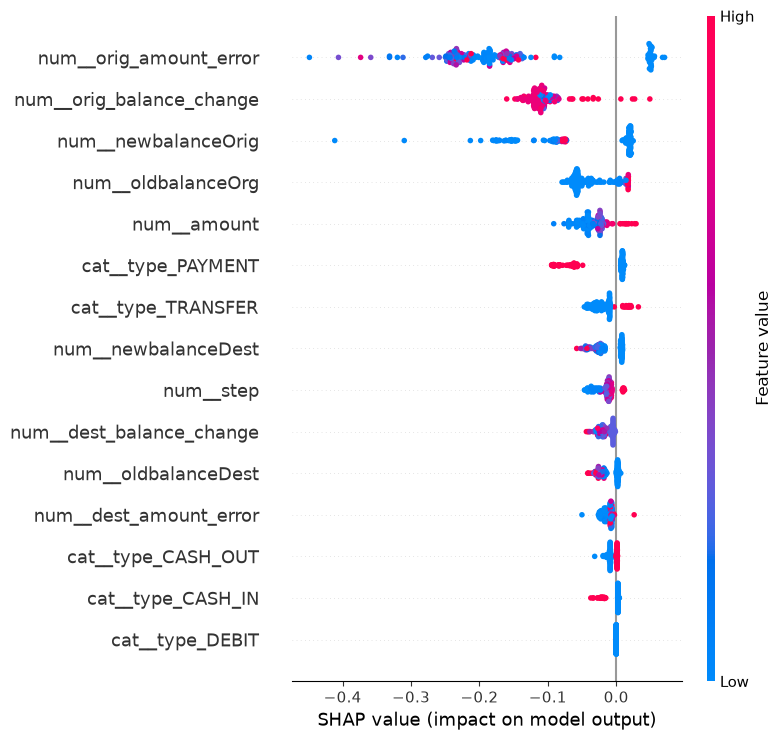

In [3]:
import shap
import matplotlib.pyplot as plt

# Explain a small batch to keep computation manageable
X_explain = X_val[:200]

explainer = shap.TreeExplainer(explain_model)
shap_values = explainer.shap_values(X_explain)

# For binary classification, select the fraud-class SHAP values
if isinstance(shap_values, list):
    fraud_shap = shap_values[1]
elif shap_values.ndim == 3:
    fraud_shap = shap_values[:, :, 1]
else:
    fraud_shap = shap_values

shap.summary_plot(
    fraud_shap,
    X_explain,
    feature_names=feature_names,
    show=True
)

In [4]:
from pathlib import Path
import joblib

# Create artifact directory at the project root
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(explain_model, MODEL_DIR / "fraud_model.joblib")
joblib.dump(preprocessor, MODEL_DIR / "preprocessor.joblib")

print("Saved:", (MODEL_DIR / "fraud_model.joblib").resolve())
print("Saved:", (MODEL_DIR / "preprocessor.joblib").resolve())

Saved: C:\Users\vinat\OneDrive\Desktop\risklens-ai\models\fraud_model.joblib
Saved: C:\Users\vinat\OneDrive\Desktop\risklens-ai\models\preprocessor.joblib
